# ***Importing Libraries***

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix)
from xgboost import XGBClassifier
import warnings
warnings.filterwarnings('ignore')

SEED = 42
keras.utils.set_random_seed(SEED)

# ***Exploratory Data Analysis (EDA)***

In [2]:
# Dataset: Adult Census Income (OpenML) - predict whether income is >50K
adult = fetch_openml("adult", version=2, as_frame=True)
df = adult.frame.copy()
df.head()

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,class
0,25,Private,226802,11th,7,Never-married,Machine-op-inspct,Own-child,Black,Male,0,0,40,United-States,<=50K
1,38,Private,89814,HS-grad,9,Married-civ-spouse,Farming-fishing,Husband,White,Male,0,0,50,United-States,<=50K
2,28,Local-gov,336951,Assoc-acdm,12,Married-civ-spouse,Protective-serv,Husband,White,Male,0,0,40,United-States,>50K
3,44,Private,160323,Some-college,10,Married-civ-spouse,Machine-op-inspct,Husband,Black,Male,7688,0,40,United-States,>50K
4,18,NaN,103497,Some-college,10,Never-married,NaN,Own-child,White,Female,0,0,30,United-States,<=50K


In [3]:
df.tail()

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,class
48837,27,Private,257302,Assoc-acdm,12,Married-civ-spouse,Tech-support,Wife,White,Female,0,0,38,United-States,<=50K
48838,40,Private,154374,HS-grad,9,Married-civ-spouse,Machine-op-inspct,Husband,White,Male,0,0,40,United-States,>50K
48839,58,Private,151910,HS-grad,9,Widowed,Adm-clerical,Unmarried,White,Female,0,0,40,United-States,<=50K
48840,22,Private,201490,HS-grad,9,Never-married,Adm-clerical,Own-child,White,Male,0,0,20,United-States,<=50K
48841,52,Self-emp-inc,287927,HS-grad,9,Married-civ-spouse,Exec-managerial,Wife,White,Female,15024,0,40,United-States,>50K


In [4]:
df.shape

(48842, 15)

In [5]:
df.columns

Index(['age', 'workclass', 'fnlwgt', 'education', 'education-num',
       'marital-status', 'occupation', 'relationship', 'race', 'sex',
       'capital-gain', 'capital-loss', 'hours-per-week', 'native-country',
       'class'],
      dtype='object')

In [6]:
df.dtypes

,0
age,int64
workclass,category
fnlwgt,int64
education,category
education-num,int64
marital-status,category
occupation,category
relationship,category
race,category
sex,category


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48842 entries, 0 to 48841
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype   
---  ------          --------------  -----   
 0   age             48842 non-null  int64   
 1   workclass       46043 non-null  category
 2   fnlwgt          48842 non-null  int64   
 3   education       48842 non-null  category
 4   education-num   48842 non-null  int64   
 5   marital-status  48842 non-null  category
 6   occupation      46033 non-null  category
 7   relationship    48842 non-null  category
 8   race            48842 non-null  category
 9   sex             48842 non-null  category
 10  capital-gain    48842 non-null  int64   
 11  capital-loss    48842 non-null  int64   
 12  hours-per-week  48842 non-null  int64   
 13  native-country  47985 non-null  category
 14  class           48842 non-null  category
dtypes: category(9), int64(6)
memory usage: 2.7 MB


In [8]:
df.describe()

,age,fnlwgt,education-num,capital-gain,capital-loss,hours-per-week
count,48842.000000,4.884200e+04,48842.000000,48842.000000,48842.000000,48842.000000
mean,38.643585,1.896641e+05,10.078089,1079.067626,87.502314,40.422382
std,13.710510,1.056040e+05,2.570973,7452.019058,403.004552,12.391444
min,17.000000,1.228500e+04,1.000000,0.000000,0.000000,1.000000
25%,28.000000,1.175505e+05,9.000000,0.000000,0.000000,40.000000
50%,37.000000,1.781445e+05,10.000000,0.000000,0.000000,40.000000
75%,48.000000,2.376420e+05,12.000000,0.000000,0.000000,45.000000
max,90.000000,1.490400e+06,16.000000,99999.000000,4356.000000,99.000000


In [9]:
df.duplicated().sum()

np.int64(52)

In [10]:
df.isnull().sum() / df.shape[0] * 100

,0
age,0.000000
workclass,5.730724
fnlwgt,0.000000
education,0.000000
education-num,0.000000
marital-status,0.000000
occupation,5.751198
relationship,0.000000
race,0.000000
sex,0.000000


In [11]:
# Target distribution (imbalanced)
df['class'].value_counts(normalize=True) * 100

,proportion
class,
<=50K,76.071823
>50K,23.928177


In [12]:
cat_cols = df.select_dtypes(exclude="number").columns.drop("class").tolist()
num_cols = df.select_dtypes(include="number").columns.tolist()
df[cat_cols].nunique()

,0
workclass,8
education,16
marital-status,7
occupation,14
relationship,6
race,5
sex,2
native-country,41


In [13]:
df['target'] = (df['class'] == '>50K').astype(int)
df.groupby('occupation')['target'].mean().sort_values(ascending=False)

,target
occupation,
Exec-managerial,0.477818
Prof-specialty,0.451069
Armed-Forces,0.333333
Protective-serv,0.313327
Tech-support,0.290456
Sales,0.267987
Craft-repair,0.226276
Transport-moving,0.204246
Adm-clerical,0.136874


In [14]:
df[num_cols + ['target']].corr()

,age,fnlwgt,education-num,capital-gain,capital-loss,hours-per-week,target
age,1.000000,-0.076628,0.030940,0.077229,0.056944,0.071558,0.230369
fnlwgt,-0.076628,1.000000,-0.038761,-0.003706,-0.004366,-0.013519,-0.006339
education-num,0.030940,-0.038761,1.000000,0.125146,0.080972,0.143689,0.332613
capital-gain,0.077229,-0.003706,0.125146,1.000000,-0.031441,0.082157,0.223013
capital-loss,0.056944,-0.004366,0.080972,-0.031441,1.000000,0.054467,0.147554
hours-per-week,0.071558,-0.013519,0.143689,0.082157,0.054467,1.000000,0.227687
target,0.230369,-0.006339,0.332613,0.223013,0.147554,0.227687,1.000000


# ***Data Visualization***

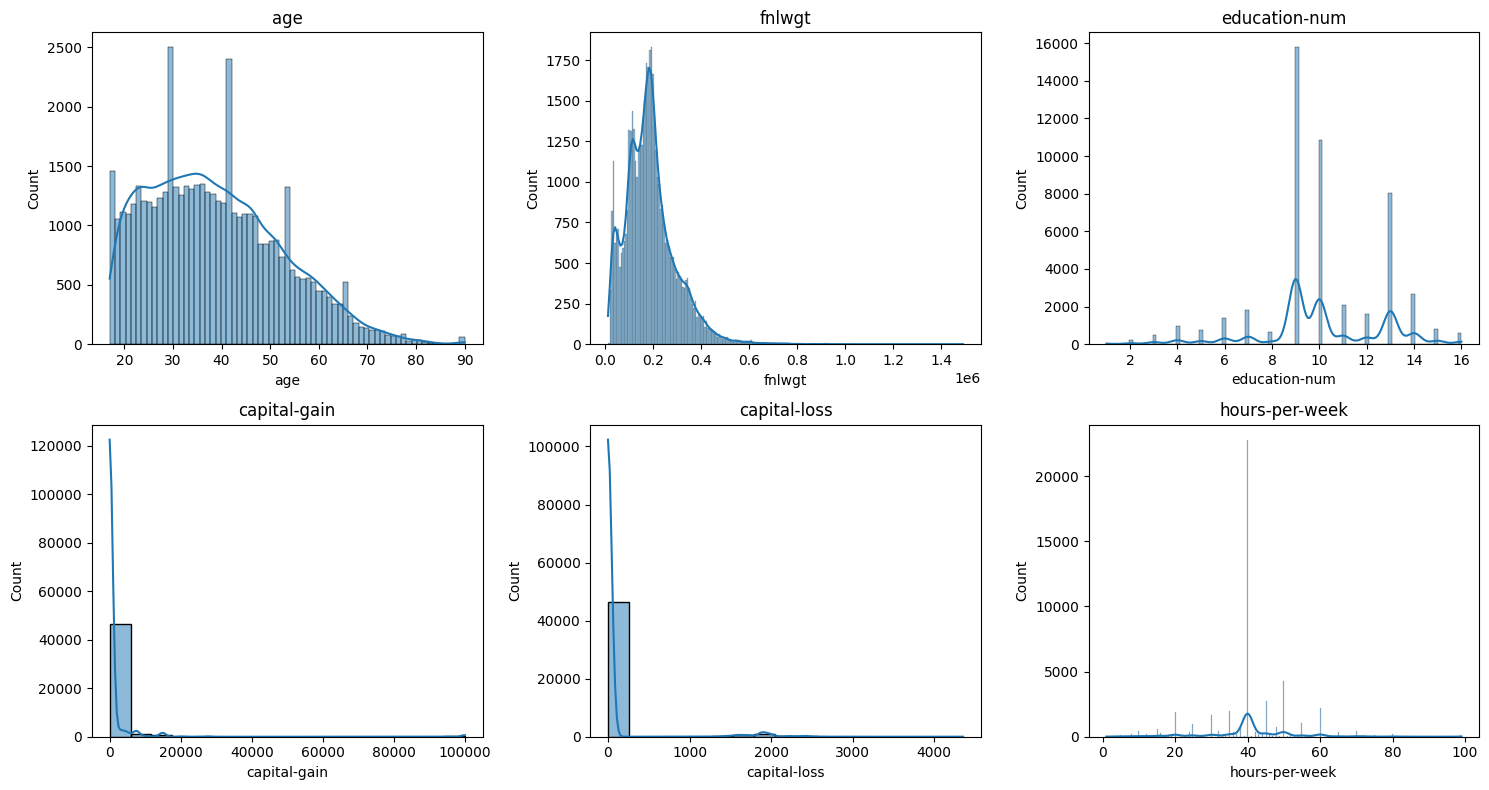

In [15]:
plt.figure(figsize=(15, 8))
for i, col in enumerate(num_cols, 1):
    plt.subplot(2, 3, i)
    sns.histplot(df[col], kde=True)
    plt.title(col)
plt.tight_layout()
plt.show()

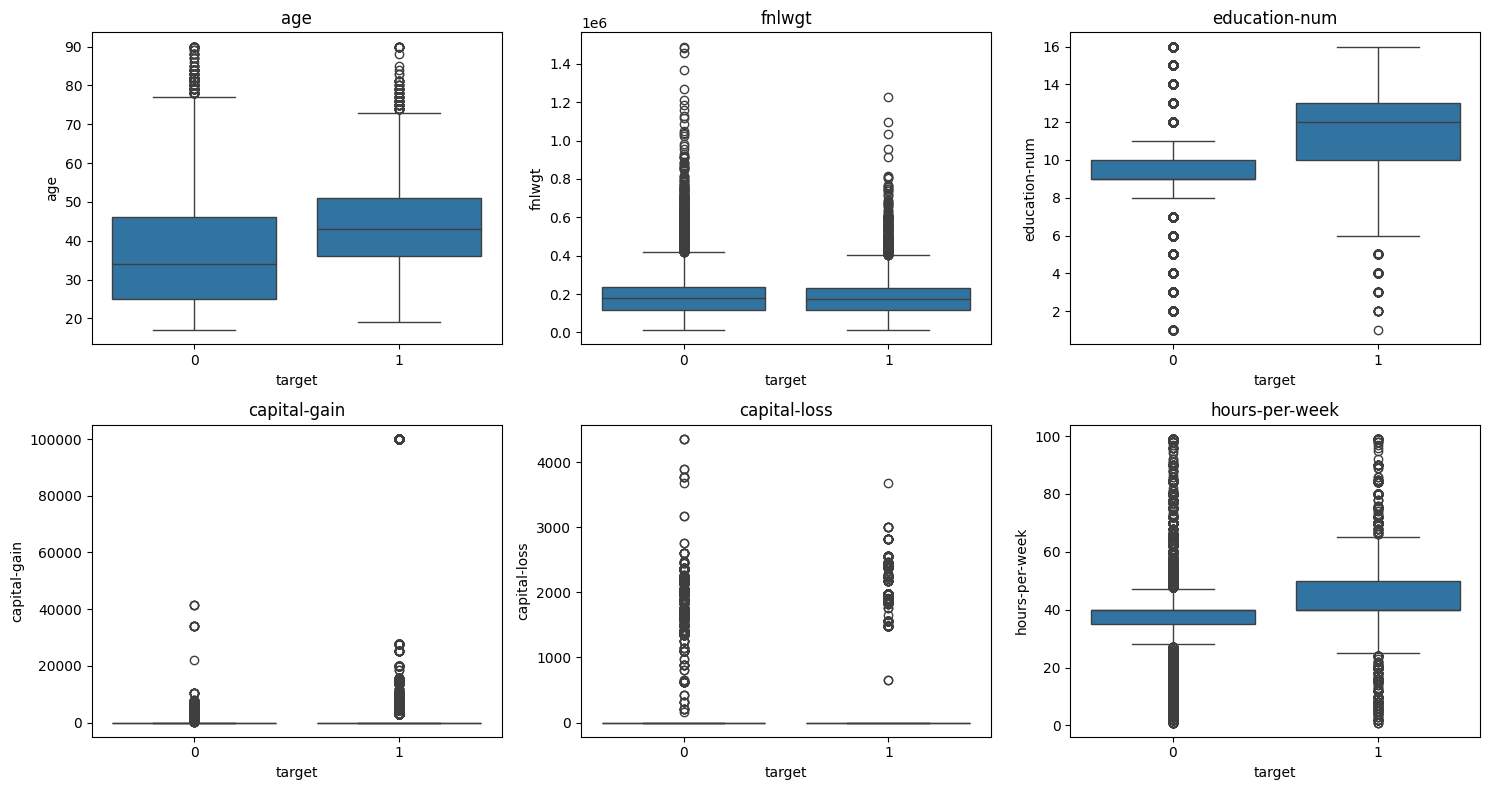

In [16]:
plt.figure(figsize=(15, 8))
for i, col in enumerate(num_cols, 1):
    plt.subplot(2, 3, i)
    sns.boxplot(x='target', y=col, data=df)
    plt.title(col)
plt.tight_layout()
plt.show()

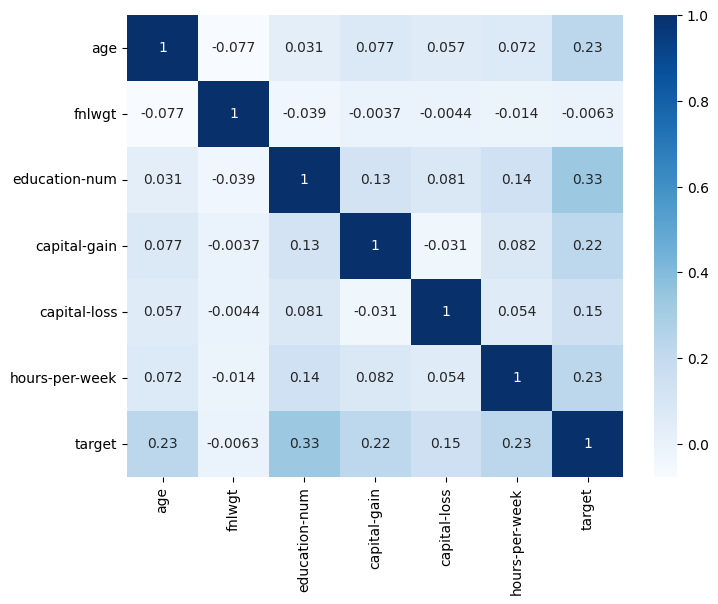

In [17]:
plt.figure(figsize=(8, 6))
sns.heatmap(df[num_cols + ['target']].corr(), annot=True, cmap='Blues')
plt.show()

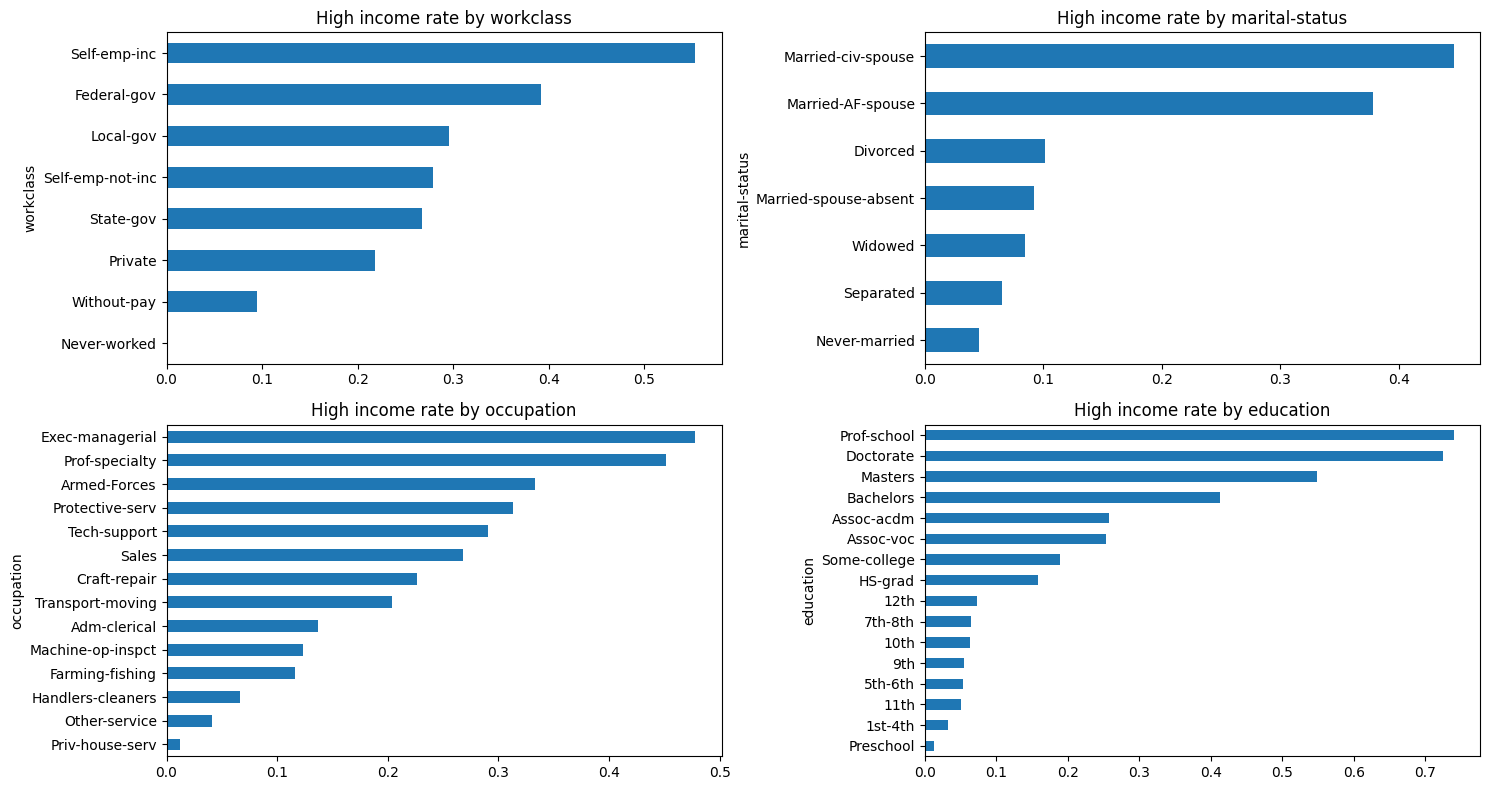

In [18]:
plt.figure(figsize=(15, 8))
for i, col in enumerate(['workclass', 'marital-status', 'occupation', 'education'], 1):
    plt.subplot(2, 2, i)
    df.groupby(col)['target'].mean().sort_values().plot(kind='barh')
    plt.title(f'High income rate by {col}')
plt.tight_layout()
plt.show()

# ***Data Preprocessing***

In [19]:
# Missing values are only in a few categorical columns, so we drop those rows
df.dropna(inplace=True)
df.shape

(45222, 16)

In [20]:
X = pd.get_dummies(df.drop(columns=['class', 'target']), drop_first=True, dtype=int)
y = df['target']
X.shape

(45222, 97)

In [21]:
# stratify keeps the same income ratio in train and test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)

In [22]:
# fitted on train only to avoid data leakage
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# ***Training & Predicting***

In [23]:
models = {
    "LogisticRegression": {
        "model": LogisticRegression(max_iter=1000),
        "params": {"C": [0.1, 1, 10]}
    },
    "RandomForest": {
        "model": RandomForestClassifier(random_state=SEED),
        "params": {"n_estimators": [100, 200], "max_depth": [10, 20, None]}
    },
    "XGBoost": {
        "model": XGBClassifier(eval_metric="logloss", verbosity=0),
        "params": {"n_estimators": [100, 200], "learning_rate": [0.05, 0.1], "max_depth": [3, 5]}
    }
}

In [24]:
# Accuracy alone is misleading with imbalanced data, so we also track Precision, Recall, F1 and ROC-AUC
results = []
best_models = {}

for name, config in models.items():

    grid = GridSearchCV(
        estimator=config['model'],
        param_grid=config['params'],
        cv=3,
        scoring='roc_auc',
        n_jobs=-1
    )

    grid.fit(X_train, y_train)

    best_model = grid.best_estimator_
    best_models[name] = best_model

    y_prob = best_model.predict_proba(X_test)[:, 1]
    y_pred = (y_prob >= 0.5).astype(int)

    results.append({
        "Model": name,
        "Best Params": grid.best_params_,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

# ***Neural Network***

In [25]:
nn_model = keras.Sequential([
    keras.Input((X_train.shape[1],)),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(1, activation="sigmoid")
])

nn_model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
nn_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │        12,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 20,865 (81.50 KB)

 Trainable params: 20,865 (81.50 KB)

 Non-trainable params: 0 (0.00 B)

In [26]:
early_stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)

history = nn_model.fit(X_train, y_train, validation_split=0.1, epochs=50, batch_size=256,
                       callbacks=[early_stop], verbose=2)

Epoch 1/50
128/128 - 1s - 10ms/step - accuracy: 0.8083 - loss: 0.4178 - val_accuracy: 0.8402 - val_loss: 0.3453
Epoch 2/50
128/128 - 0s - 3ms/step - accuracy: 0.8357 - loss: 0.3546 - val_accuracy: 0.8466 - val_loss: 0.3365
Epoch 3/50
128/128 - 0s - 3ms/step - accuracy: 0.8419 - loss: 0.3423 - val_accuracy: 0.8469 - val_loss: 0.3326
Epoch 4/50
128/128 - 0s - 3ms/step - accuracy: 0.8451 - loss: 0.3357 - val_accuracy: 0.8499 - val_loss: 0.3294
Epoch 5/50
128/128 - 0s - 3ms/step - accuracy: 0.8466 - loss: 0.3314 - val_accuracy: 0.8494 - val_loss: 0.3267
Epoch 6/50
128/128 - 0s - 3ms/step - accuracy: 0.8508 - loss: 0.3246 - val_accuracy: 0.8496 - val_loss: 0.3261
Epoch 7/50
128/128 - 0s - 4ms/step - accuracy: 0.8512 - loss: 0.3225 - val_accuracy: 0.8521 - val_loss: 0.3239
Epoch 8/50
128/128 - 1s - 4ms/step - accuracy: 0.8511 - loss: 0.3222 - val_accuracy: 0.8546 - val_loss: 0.3238
Epoch 9/50
128/128 - 1s - 5ms/step - accuracy: 0.8513 - loss: 0.3168 - val_accuracy: 0.8560 - val_loss: 0.3230


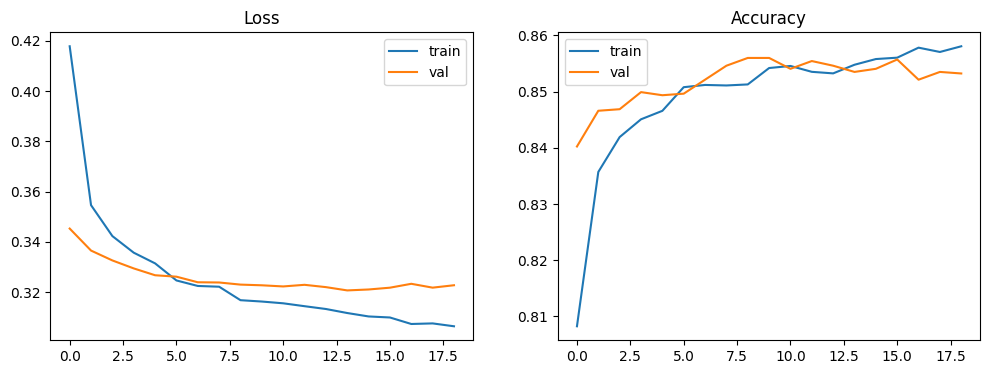

In [27]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["loss"], label="train")
plt.plot(history.history["val_loss"], label="val")
plt.title("Loss")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["accuracy"], label="train")
plt.plot(history.history["val_accuracy"], label="val")
plt.title("Accuracy")
plt.legend()

plt.show()

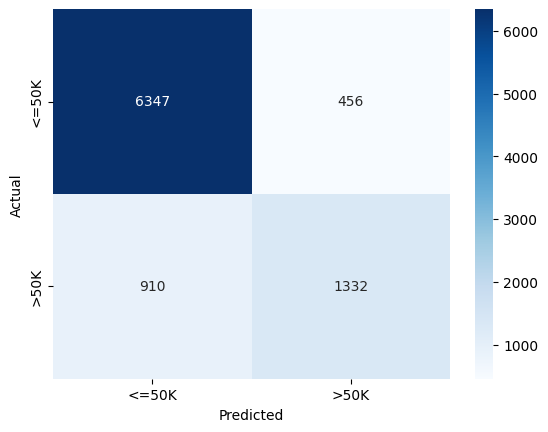

In [28]:
y_prob = nn_model.predict(X_test, verbose=0).ravel()
y_pred = (y_prob >= 0.5).astype(int)

results.append({
    "Model": "Neural Network",
    "Best Params": "-",
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred),
    "Recall": recall_score(y_test, y_pred),
    "F1": f1_score(y_test, y_pred),
    "ROC-AUC": roc_auc_score(y_test, y_prob)
})

cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['<=50K', '>50K'], yticklabels=['<=50K', '>50K'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

# ***Model Comparison***

In [29]:
results_df = pd.DataFrame(results)
results_df = results_df.sort_values(by="ROC-AUC", ascending=False)
results_df.reset_index(drop=True, inplace=True)
results_df

,Model,Best Params,Accuracy,Precision,Recall,F1,ROC-AUC
0,XGBoost,"{'learning_rate': 0.1, 'max_depth': 5, 'n_esti...",0.865561,0.771142,0.650758,0.705854,0.927275
1,RandomForest,"{'max_depth': 20, 'n_estimators': 200}",0.857933,0.785672,0.586976,0.671943,0.914444
2,Neural Network,-,0.848977,0.744966,0.594112,0.661042,0.907455
3,LogisticRegression,{'C': 0.1},0.845882,0.731441,0.597681,0.657830,0.904511


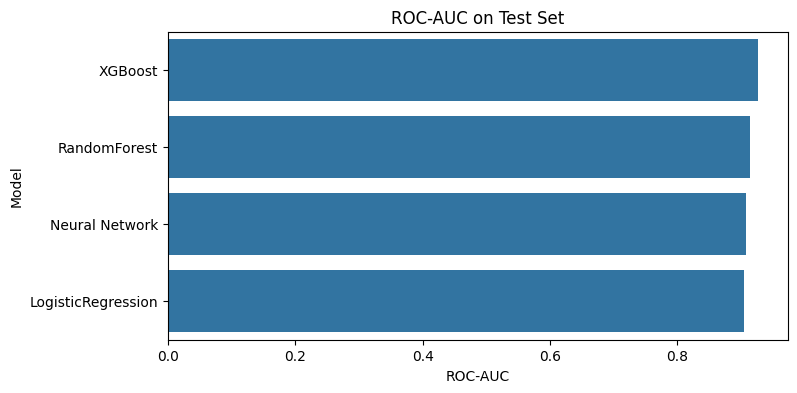

In [30]:
plt.figure(figsize=(8, 4))
sns.barplot(x="ROC-AUC", y="Model", data=results_df)
plt.title("ROC-AUC on Test Set")
plt.show()

# ***Feature Importance***

In [31]:
importance = pd.Series(best_models["XGBoost"].feature_importances_, index=X.columns)
importance.sort_values(ascending=False).head(15)

,0
marital-status_Married-civ-spouse,0.428914
education-num,0.062449
capital-gain,0.049376
occupation_Other-service,0.038157
relationship_Own-child,0.031061
occupation_Exec-managerial,0.029520
capital-loss,0.021590
occupation_Prof-specialty,0.021315
occupation_Farming-fishing,0.019077
age,0.013627


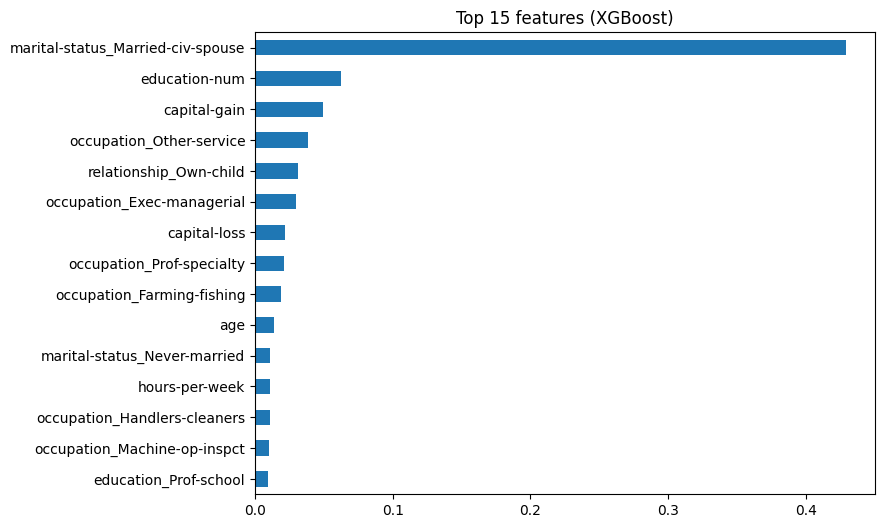

In [32]:
plt.figure(figsize=(8, 6))
importance.sort_values().tail(15).plot(kind="barh")
plt.title("Top 15 features (XGBoost)")
plt.show()

# ***Saving the Model***

In [33]:
joblib.dump(best_models["XGBoost"], "xgboost_income.pkl")
joblib.dump(scaler, "scaler.pkl")
joblib.dump(list(X.columns), "columns.pkl")
nn_model.save("income_nn.keras")